#### Identifying the number of cores and initializing parallelization

In [ ]:
import os # library for interacting with the opertating system
from joblib import cpu_count  # How many CPUs are available
from threadpoolctl import threadpool_limits # Controls how many CPU threads are used by libraries like BLAS


TOTAL_CPUS = cpu_count(only_physical_cores=False) # 'only_physical_cores=False' means count logical CPUs not only physical CPUs


N_JOBS = max(1, TOTAL_CPUS - 2) # ensures that the thread count is never less than 0

print(f"Available CPUs: {TOTAL_CPUS}")
print(f"CPUs allocated: {N_JOBS}")

Available CPUs: 32
CPUs allocated: 30


n2p2 dataset might look like,

```python
begin                                       --- begining of one atomic configuration
lattice 5.0 0.0 0.0
lattice 0.0 5.0 0.0
lattice 0.0 0.0 5.0
atom 0.0 0.0 0.0 Si 0.0 0.0 0.0 0.0 0.0
atom 2.5 2.5 2.5 Si 0.0 0.0 0.0 0.0 0.0
energy -10.5
charge 0.0
end                                         --- end of one atomic configuration
```

Task -- getting atomic structures as ASE objects and energy values separately

In [ ]:
from pathlib import Path # class 'Path' that helps locating the files

from ase import Atoms # class 'Atoms' represents atomic structures
from dscribe.descriptors import ACSF # library for generating descriptors of atomic structures

import numpy as np

from sklearn.model_selection import train_test_split # to divide a dataset into train set and test set
from sklearn.preprocessing import StandardScaler # to standardize numerical features
from sklearn.neural_network import MLPRegressor  # neural network model provided by scikit-learn
from sklearn.metrics import mean_absolute_error, mean_squared_error

from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits #controls how many CPU threads are used by libraries like BLAS

import matplotlib.pyplot as plt

'Atom Object' is like,

```python
atoms = Atoms(
    symbols=["Fe", "Fe"],
    positions=[[0, 0, 0], [2, 2, 2]]
)
```

They can store elements, coordinates, unit cell dimensions, periodic boundry conditions

# TASK 1 - Extract data from the data file 

Internal Helper Functions 

+ not called directly by the user
+ supports the main function

_ at the beginning indicates that this is intended to be an internal helper function

In [ ]:
def _parse_n2p2_block(block): # Internal Helper function to parse a single n2p2 block and extract atomic structure and energy information from the lines in n2p2 file
    symbols = []                # Store element symbols of atoms
    positions = []          # Store atomic positions in cartesian coordinates
    cell = []               # Stores lattice vectors describing the simulation cell
    energy = None           # Stores reference energy 


    for line in block:
        parts = line.split() # separate the strings in a line based on whitespace

        if not parts:
            continue # if the list parts is empty, skip to next line

        if parts[0] == "lattice":
            cell.append([float(x) for x in parts[1:4]]) # Make the vector with direction values of [x,y,z] ex - from "lattice 0.0 5.0 0.0" extract [0.0, 5.0, 0.0]
            has_cell = True # lattice information for this block is found successfully

        elif parts[0] == "atom":
            positions.append([float(x) for x in parts[1:4]]) # poistion of the atom to the list positions, ex - from "atom 0.0 0.0 0.0 H" extract [0.0, 0.0, 0.0]
            symbols.append(parts[4]) # Type of atom to the list symbols, ex - from "atom 0.0 0.0 0.0 Si" extract "Si"
                                       # ignores all the other information in the line, like charge, mass, etc. 

        elif parts[0] == "energy":
            energy = float(parts[1]) # extract the reference energy value

    if energy is None:
        raise ValueError("Energy missing in n2p2 block") # raising an error if energy is not found in the block

   # if not symbols:
        #raise ValueError("No atoms found in n2p2 block") # raising an error if no atoms are found in the block

    atoms = Atoms( #Converst extracted information into ASE Atoms object
        symbols=symbols,
        positions=positions,
        cell=cell if len(cell) == 3 else None, # if exactly 3 lattice vectors were found use it or set cell to None
        pbc=(len(cell) == 3) # if exactly 3 lattice vectors are present, set periodic boundary conditions to True ( consider cell as periodic)
    )

    return atoms, energy

A 'block' looks like this
 
```python
block = [
    "lattice 5.0 0.0 0.0",
    "lattice 0.0 5.0 0.0",
    "lattice 0.0 0.0 5.0",
    "atom 0.0 0.0 0.0 Si 0.0 0.0 0.0 0.0 0.0",
    "energy -10.5"
]
```

<img src="images/cell example.png" width="300">

In [ ]:
def read_n2p2(path, n_jobs=N_JOBS): # function to read the entire dataset from n2p2 file

    current_block = [] #temporarily store the lines of one configuration
    blocks = [] # in the end this will contain all the atomic configuration blocks
    inside = False # tracks whether program is currently reading a configuration or not

    with open(path, "r") as f: # 'as file' assignss the opened file to the variable 'file' which can be used to read the file 
        for line in f:
            line = line.strip() #.strip() method removes whitespace at the beginning and end of each line, including newline characters

            if line == "begin": # when encounters 'begin', it knows a new atomic configuration is starting
                current_block = []
                inside = True # program is now reading a configuration

            elif line == "end" and inside:
                blocks.append(current_block)
                inside = False

            elif inside: # if the program is currently reading a configuration, it adds the line to the current block
                current_block.append(line)

    results = Parallel( # Parallel - a function Class by joblib
        n_jobs=n_jobs,
        backend="loky"
    )(
        delayed(_parse_n2p2_block)(block) # main process execute inside the delayed function - allows the function to be executed in parallel across multiple CPU cores.
        for block in blocks # iterates over all the configurations
    )

    atoms_list = [item[0] for item in results] # extract and make a list of elements in the datafile
    energies = np.array([item[1] for item in results]) # extract and make a list of energies in the datafile , convert to a numpy array for easier calculations

    return atoms_list, energies


atoms_list, energies = read_n2p2(
    "input.data",
    n_jobs=N_JOBS
)

print("Number of structures:", len(atoms_list))
print("Energy shape:", energies.shape)

Number of structures: 51702
Energy shape: (51702,)


# TASK 2 - Building descriptors

Task - convert those atomic structures into numerical features using Atom-Centered Symmetry Functions (ACSF)

Descriptor - numerical representation that describes the local atomic environment, including the chemical species, spatial arrangement of neighboring atoms

ACSF

- local environment surrounding an atom using mathematical functions based on distances and angles

- provides features that are designed to be invariant to translation and rotation, and to permutations of equivalent atoms

- rotating or translating a structure should not change its potential energy


### Gaussian Radial Symmetry Function

A typical expression is:

$$
G_i^2 = \sum_{j \neq i} e^{-\eta(R_{ij}-R_s)^2} f_c(R_{ij})
$$

#### Where:

| Symbol | Meaning |
|--------|---------|
| $i$ | Central atom |
| $j$ | Neighboring atom |
| $R_{ij}$ | Distance between atoms $i$ and $j$ |
| $\eta$ | Controls the width of the Gaussian function |
| $R_s$ | Shifts the center of the Gaussian |
| $f_c$ | Cutoff function |


### Gaussian Angular Symmetry Function

consider a central atom \(i\) and two neighboring atoms \(j\) and \(k\), The angular descriptor captures information about the angle θ between neighboring atoms.

<img src="images/Angular symmetry functions.png" width="300">

### Averaging atomic descriptors


Consider the following matrix:

###### Example Atomic Descriptor Matrix

| Atom | Feature 1 | Feature 2 | Feature 3 |
|------|-----------|-----------|-----------|
| Atom 1 | 2 | 4 | 6 |
| Atom 2 | 4 | 6 | 8 |
| Atom 3 | 6 | 8 | 10 |
| **Average** | **4** | **6** | **8** |

`axis=0` calculates the mean down each column, across all atoms.


```python
np.mean(atomic_descriptors, axis=0)
```

**Result:**

```python
[4.0, 6.0, 8.0]
```

This is now one feature vector representing the entire structure.


Mathematically:

$$
\overline{G}_k = \frac{1}{N}\sum_{i=1}^{N}G_{ik}
$$

Where:

- $N$ = Number of atoms in the structure.
- $G_{ik}$ = Descriptor feature $k$ for atom $i$.
- $\overline{G}_k$ = Average descriptor feature $k$.

#### Why Average?

Different atomic structures may contain different numbers of atoms.

For example, one structure might contain 10 atoms and another 20 atoms.

Averaging converts both into fixed length vectors, making them suitable for a standard neural network.

limitation: averaging loses some information about individual atomic environments. In addition, it does not explicitly account for the number of atoms, which matters when predicting total energy rather than energy per atom.

this method is convenient for a simple task, but it is not equivalent to a full atom centered MLIP.


In [ ]:
# Generate one feature vector for each atomic configuration

species = sorted({ # Python set is created using curley brackets , to automatically remove duplicates
    symbol          # Sorting is done to ensure consistent ordering of species across different configurations, the same order will be used again for traning and etc.
    for atoms in atoms_list
    for symbol in atoms.get_chemical_symbols() # ASE method - returns the chemical symbols of every atom in a structure , return would be smth like ["Fe", "Ni"]
})

# ACSF descriptor generator

acsf = ACSF( 
    species=species, # tells which elements exist in dataset
    r_cut=6.0, # cutoff radius - only the atoms inside this radius contribute to the descriptor

        # radial symmetry functions - how neighboring atoms are distributed at different distances from a central atom
    g2_params=[
            [1.0, 0.0], # [neta, Rs] - neta controls the width of the Gaussian function, Rs shifts the center of the Gaussian function (above equation)
            [1.0, 2.0],
            [1.0, 4.0] # 3 Gaussian functions allow the descriptor to distinguish between atomic environments with different neighbor distances.
    ],

        # angular symmetry functions - describe the relative arrangement of three atoms
    g4_params=[
            [1.0, 1.0, 1.0], # [neta, zeta, lambda]
            [1.0, 1.0, -1.0] # neta - Controls the distance dependent exponential term, zeta - Controls angular resolution, lambda - Controls the angular preference
    ] # here lambda is the only difference - distinguish atomic arrangements that may have similar radial distances but different bond angles.
)


def _calculate_descriptor(atoms):
    atomic_descriptors = acsf.create(atoms) # calculates a separate descriptor vector for each atom in the strcture

    return np.mean(
        atomic_descriptors, # averaging atomic descriptors to get a single descriptor vector for the entire atomic configuration
        axis=0 #takes mean of the each column (feature) of all atoms in the structure
    )


def build_descriptors(atoms_list, n_jobs=N_JOBS):

    
    descriptors = Parallel(
        n_jobs=n_jobs,
        backend="loky" # uses separate python processes - let independent descriptor calculations to run concurrently
    )(
        delayed(_calculate_descriptor)(atoms) # prepares the calculation for one atomic configuration.
        for atoms in atoms_list 
    )

    return np.asarray(descriptors)


X = build_descriptors(
    atoms_list,
    n_jobs=N_JOBS
)

print("Descriptor matrix shape:", X.shape)


Descriptor matrix shape: (51702, 6)


# TASK 3 - Train a Neural Network

independent variables - the feature matrix containing ACSF descriptors
dependent variable - the reference energies

```text

                    Train/Test Data Split
                    (80% Train, 20% Test)
                           |
                           v
                    StandardScaler
                    (Feature Scaling)
                           |
                           v
                     MLPRegressor
                (Neural Network Training)
                           |
                           v
                  Energy Prediction
                           |
                           v
        Trained Model + Scaler + Test Predictions
```
                


X, y will look like as follows:


| Structure | Descriptor vector (X) | Energy (y) |
|-----------|------------------------|------------|
| 1 | [0.2, 0.4, 0.6] | -10.5 |
| 2 | [0.3, 0.5, 0.7] | -11.2 |
| 3 | [0.4, 0.6, 0.8] | -12.3 |
| 4 | [0.5, 0.7, 0.9] | -13.1 |

After splitting data,

| Variable | Contains |
|----------|----------|
| `X_train` | ACSF descriptors used for training |
| `X_test` | ACSF descriptors used for testing |
| `y_train` | Reference energies used for training |
| `y_test` | Reference energies used for testing |

For example, if we have 100 structures and 20 features:

```python
X_train.shape  # (80, 20) - two dimensional matrix
X_test.shape   # (20, 20)

y_train.shape  # (80,) - one dimentional array
y_test.shape   # (20,)

##### Scaling


The mathematical formula is:

$$
z = \frac{x-\mu}{\sigma}
$$

Where:

- $x$ = original feature value.
- $\mu$ = mean of that feature in the training dataset.
- $\sigma$ = standard deviation of that feature in the training dataset.
- $z$ = standardized feature value.

ex:

```python
[10, 20, 30]
```

mean is:

$$
\mu = \frac{10+20+30}{3} = 20
$$

population standard deviation is approximately:

$$
\sigma = \sqrt{\frac{(10-20)^2+(20-20)^2+(30-20)^2}{3}}
= 8.165
$$

The standardized values become approximately:

```python
[10, 20, 30] ---> [-1.225, 0.0, 1.225]
```


##### ReLu Activation Function - Rectified Linear Unit

Introduces nonlinearity into the network, enabling it to learn more complex relationships than a simple linear regression

- If use linear relationships, it allows the model to predict negative energy values as well


Its mathematical expression is:

$$
f(x) = \max(0,x)
$$

This means:

$$
f(x) =
\begin{cases}
0 & x \leq 0 \\
x & x > 0
\end{cases}
$$



##### Adam - optimization algorithm (Adaptive Moment Estimation)

- Neural network contains adjustable parameters called weights and biases.

- The objective is to find values for these parameters that minimize the prediction error.

- Adam updates these parameters iteratively using gradient information and adaptive learning rates.


In simplified form:

$$
w_{\text{new}} = w_{\text{old}} - \text{update}
$$


- Adam calculates the update using estimates of the first and second moments of the gradients.

- It is commonly used because it performs well for many neural network training problems.

In [ ]:



def train_nn(X, y, n_threads=N_JOBS): # X - ACSF feature matrix, y - reference energies, Maximum number of BLAS threads requested = CPU thread counts counted before

    X_train, X_test, y_train, y_test = train_test_split( # randomly splits data into train and test sets
        X, # X.shape = (number of configurations, number of features) - 2D array
        y, # y.shape = (number of configurations,) - 1D array
        test_size=0.2, 
        random_state=42 # By default, train_test_split shuffles the data before splitting , using a fixed random seed makes the split reproducible
    )

    scaler = StandardScaler()

    X_train_scaled = scaler.fit_transform(X_train) # fit - calculates the mean and standard deviation of each feature using X_train
                                                    # transform - standardizes the features by subtracting the mean and dividing by the standard deviation, resulting in a new feature matrix with zero mean and unit variance
    X_test_scaled = scaler.transform(X_test) # should not calculate new scaling statistics using the testing dataset, use the mean and standard deviation already calculated from the training data


    # Hidden layers - allow the neural network to learn nonlinear relationships between ACSF descriptors and reference energies


    model = MLPRegressor(
        hidden_layer_sizes=(64, 32), # two hidden layers, first with 64 neurons and second with 32 neurons
        activation="relu", # activation function used in the hidden layers
        solver="adam", # the optimization algorithm used to train the neural network
        max_iter=2000, 
        # Adam solver - an iteration corresponds to one epoch: one pass through the training dataset, with weight updates performed over mini batches , the model can train for up to 2000 epochs.
        # Training may stop earlier if the convergence criteria are satisfied

        random_state=42 # controls random processes within the neural network ex: initialization of weights and aspects of the training procedure
    )

    with threadpool_limits(
        limits=n_threads, # limits maximum number of BLAS threads to use
        user_api="blas"
    ):
        model.fit(X_train_scaled, y_train)

        predictions = model.predict(X_test_scaled) # predict energies for the test set using the trained model by model.fit

    return { # dictionary containing the trained model, scaler, training and testing data, and predictions
        "model": model,
        "scaler": scaler,
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train,
        "y_test": y_test,
        "predictions": predictions
    }


result = train_nn(
    X,
    energies,
    n_threads=N_JOBS
)

print("Training completed.")


Training completed.


# TASK 4

###### BLAS - Basic Linear ALgebra Subprogram

- accelerate mathematical operations such as matrix multiplication.
- In neural networks, matrix multiplication is used to calculate the outputs of neurons

MAE: 7.872890 eV
RMSE: 11.140853 eV


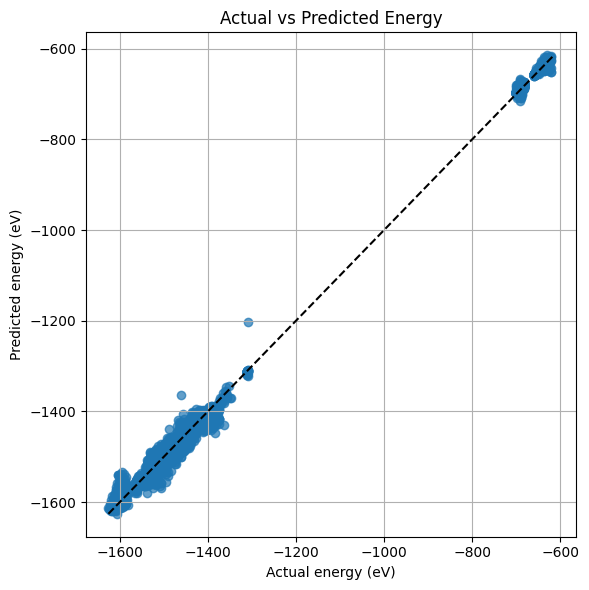

In [ ]:


def evaluate_model(result, n_threads=N_JOBS): 

    model = result["model"] # retrieve the trained neural network model from the result dictionary
    scaler = result["scaler"] 

    X_test = result["X_test"]
    y_test = result["y_test"]

    X_test_scaled = scaler.transform(X_test) # using the same scaler to standardize the test data, ensuring that the test data is transformed using the same mean and standard deviation as the training data

    with threadpool_limits(
        limits=n_threads,
        user_api="blas"
    ):
        y_pred = model.predict(X_test_scaled)

   
    mae = mean_absolute_error(y_test, y_pred) # compare predicted energies with reference energies using mean absolute error (MAE) metric

    rmse = np.sqrt(
        mean_squared_error(y_test, y_pred) 
    )

    print(f"MAE: {mae:.6f} eV")
    print(f"RMSE: {rmse:.6f} eV")

    
    plt.figure(figsize=(6, 6))

    plt.scatter(
        y_test,
        y_pred,
        alpha=0.7
    )

    limits = [
        min(y_test.min(), y_pred.min()), # identify the minimum value between the actual and predicted energies to set the lower limit of the plot
        max(y_test.max(), y_pred.max())
    ]

    plt.plot(
        limits,
        limits,
        "k--"
    )

    plt.xlabel("Actual energy (eV)")
    plt.ylabel("Predicted energy (eV)")
    plt.title("Actual vs Predicted Energy")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return mae, rmse


mae, rmse = evaluate_model(
    result,
    n_threads=N_JOBS
)


# TASK 5

In [ ]:


def _predict_batch(model, X_batch): # predict energy for one batch of input data

    
    with threadpool_limits(
        limits=1, # limits maximum number of BLAS threads to use for each batch prediction, preventing each worker from spawning many BLAS threads
        user_api="blas"  # if each worker launches multiple BLAS threads, it can lead to oversubscription of CPU resources and degrade performance.
    ):
        return model.predict(X_batch) 


def predict_energy(result, X, n_jobs=N_JOBS): # Devide input data into batches, and predict energies using the trained model
 
    X = np.asarray(X) # ensure X is a numpy array

    if len(X) == 0: # it returns an empty array without attempting prediction if input contains zero samples
        return np.array([])

    
    if X.ndim == 1: # how many dimensions the array has, if it is 1D, it means there is only one descriptor vector, so we need to reshape it to 2D for the model to process it correctly
        X = X.reshape(1, -1)  # -1 determines the size of the second dimension based on the size of the first dimension, ensuring that the total number of elements remains the same



    
    X_scaled = result["scaler"].transform(X) # use the same scalar as before

    
    if n_jobs == 1 or len(X_scaled) < 100: # avoids the overhead of launching and communicating with multiple processes for small prediction tasks
        return result["model"].predict(X_scaled)

    
    n_workers = min(n_jobs, len(X_scaled)) # prevents the function from requesting more workers than input samples

    batches = np.array_split(
        X_scaled,
        n_workers
    )   # Devide into equal sized batches for each worker, If the number of samples cannot be divided evenly, np.array_split() distributes the remainder across the first batches

    
    predictions = Parallel(
        n_jobs=n_workers,
        backend="loky"
    )(
        delayed(_predict_batch)( # Prepares a call to _predict_batch() so Joblib can schedule it
            result["model"],
            batch
        )
        for batch in batches  # for each batch in batches, create one prediction task for every batch, which will be executed in parallel, results then stored in the list predictions
    )

    return np.concatenate(predictions) # combines the predictions from all batches into a single array


# example code to predict the first 10 structures
predicted_energies = predict_energy(
    result,
    X[:10],
    n_jobs=N_JOBS
)

print("Predicted energies (eV):")
print(predicted_energies)


Predicted energies (eV):
[-1404.7792476  -1414.49527552 -1395.43825377 -1437.01295327
 -1397.70262581 -1409.75469468 -1422.17438697 -1427.46305917
 -1396.96037037 -1408.39045262]
